# Credit Card Fraud: Analysis and Business Impact

**Goal:** find where fraud happens, compare models that handle extreme class imbalance, and choose an alert threshold using **money saved**, not accuracy.

**Why not accuracy?** Fraud is a tiny share of transactions. A model that says "no fraud" every time would still look ~99.8% accurate. So this notebook uses precision, recall, F1, ROC-AUC and PR-AUC.

**Data:** Kaggle `creditcard.csv` (`creditcard.csv` or `creditcard.csv.zip`, in the same folder as this notebook).

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score,
                             precision_recall_curve)

RANDOM_STATE = 42
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 2. Load data and basic checks

In [2]:
import os
DATA_FILE = "creditcard.csv" if os.path.exists("creditcard.csv") else "creditcard.csv.zip"
df = pd.read_csv(DATA_FILE)

print("Rows, columns:", df.shape)
print("Missing values:", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

counts = df["Class"].value_counts()
print("\nLegitimate:", int(counts[0]), "| Fraud:", int(counts[1]))
print(f"Fraud rate: {counts[1] / len(df) * 100:.3f}%")

Rows, columns: (284807, 31)
Missing values: 0


Duplicate rows: 1081

Legitimate: 284315 | Fraud: 492
Fraud rate: 0.173%


## 3. Where does fraud happen?

**Assumption:** `Time` is seconds since the first transaction in the dataset. Treating `Time` as hours from the start of day 1 gives an *approximate* hour-of-day. The real clock time is not given, so read hour patterns with care.

,transactions,frauds,fraud_rate_pct
Hour,,,
0,7695,6,0.078
1,4220,10,0.237
2,3328,57,1.713
3,3492,17,0.487
4,2209,23,1.041
5,2990,11,0.368
6,4101,9,0.219
7,7243,23,0.318
8,10276,9,0.088


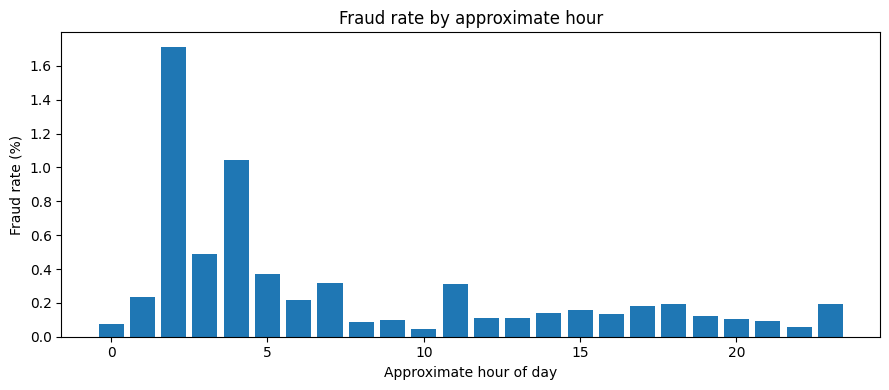

In [3]:
df["Hour"] = ((df["Time"] // 3600) % 24).astype(int)

by_hour = df.groupby("Hour")["Class"].agg(transactions="count", frauds="sum")
by_hour["fraud_rate_pct"] = by_hour["frauds"] / by_hour["transactions"] * 100
display(by_hour)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(by_hour.index, by_hour["fraud_rate_pct"])
ax.set_xlabel("Approximate hour of day")
ax.set_ylabel("Fraud rate (%)")
ax.set_title("Fraud rate by approximate hour")
plt.tight_layout()
plt.savefig("fraud_by_hour.png", dpi=150)
plt.show()

,transactions,frauds,fraud_rate_pct
AmountBand,,,
0-10,100264,249,0.248
10-50,90781,57,0.063
50-100,37254,56,0.150
100-500,47366,95,0.201
500+,9142,35,0.383


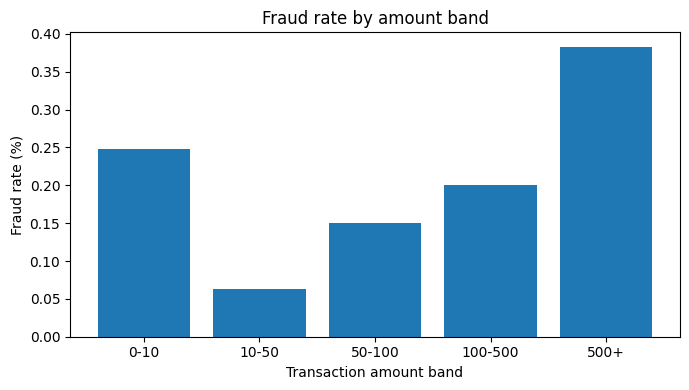

In [4]:
bins = [-0.01, 10, 50, 100, 500, np.inf]
labels = ["0-10", "10-50", "50-100", "100-500", "500+"]
df["AmountBand"] = pd.cut(df["Amount"], bins=bins, labels=labels)

by_band = df.groupby("AmountBand", observed=True)["Class"].agg(transactions="count", frauds="sum")
by_band["fraud_rate_pct"] = by_band["frauds"] / by_band["transactions"] * 100
display(by_band)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(by_band.index.astype(str), by_band["fraud_rate_pct"])
ax.set_xlabel("Transaction amount band")
ax.set_ylabel("Fraud rate (%)")
ax.set_title("Fraud rate by amount band")
plt.tight_layout()
plt.savefig("fraud_by_amount_band.png", dpi=150)
plt.show()

## 4. Train / validation / test split

- **Train (60%)**: fit the models.
- **Validation (20%)**: choose the alert threshold.
- **Test (20%)**: final, untouched results.

`stratify` keeps the same fraud rate in every part. `Amount` is scaled using the training data only. `V1`-`V28` are already scaled (PCA output).

In [5]:
features = [f"V{i}" for i in range(1, 29)] + ["Amount"]
X = df[features]
y = df["Class"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=RANDOM_STATE)

scaler = StandardScaler().fit(X_train[["Amount"]])

def scale(part):
    part = part.copy()
    part["Amount"] = scaler.transform(part[["Amount"]])
    return part

Xs_train, Xs_val, Xs_test = scale(X_train), scale(X_val), scale(X_test)

# Raw (unscaled) amounts, needed later for the money calculation
amt_val = df.loc[X_val.index, "Amount"].values
amt_test = df.loc[X_test.index, "Amount"].values

print("Train:", len(X_train), "| frauds:", int(y_train.sum()))
print("Val:  ", len(X_val),   "| frauds:", int(y_val.sum()))
print("Test: ", len(X_test),  "| frauds:", int(y_test.sum()))

Train: 170884 | frauds: 295
Val:   56961 | frauds: 98
Test:  56962 | frauds: 99


## 5. Evaluation helper

In [6]:
def evaluate(name, y_true, score, pred):
    return {
        "Model": name,
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, score),
        "PR_AUC": average_precision_score(y_true, score),
        "Flagged": int(pred.sum()),
    }

## 6. Model 1: Logistic Regression (class-weighted)

`class_weight="balanced"` makes a missed fraud count much more than a missed legitimate transaction during training.

In [7]:
lr = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)
lr.fit(Xs_train, y_train)

p_lr_val = lr.predict_proba(Xs_val)[:, 1]
p_lr_test = lr.predict_proba(Xs_test)[:, 1]
print("Logistic Regression done")

Logistic Regression done


## 7. Model 2: Random Forest (class-weighted)

This may take a few minutes on a laptop. That is normal.

In [8]:
rf = RandomForestClassifier(
    n_estimators=100, max_depth=12, min_samples_leaf=5,
    class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(Xs_train, y_train)

p_rf_val = rf.predict_proba(Xs_val)[:, 1]
p_rf_test = rf.predict_proba(Xs_test)[:, 1]
print("Random Forest done")

Random Forest done


## 8. Model 3: K-Means as an anomaly detector

Idea: learn what *normal* transactions look like (clusters of legitimate rows only). A transaction far from every cluster centre is suspicious. Anomaly score = distance to the nearest centre. Flag a transaction if its score is above the 99th percentile of normal training scores (so about 1% of normal data would be flagged).

In [9]:
legit_train = Xs_train[y_train == 0]
km = KMeans(n_clusters=8, n_init=10, random_state=RANDOM_STATE).fit(legit_train)

def km_score(data):
    return km.transform(data).min(axis=1)

km_threshold = np.percentile(km_score(legit_train), 99)
s_km_test = km_score(Xs_test)
print("K-Means done")

K-Means done


## 9. Model comparison (test set)

Logistic Regression and Random Forest use the default 0.5 cut-off here. The cost-based threshold comes later.

In [10]:
rows = [
    evaluate("Logistic Regression", y_test, p_lr_test, (p_lr_test >= 0.5).astype(int)),
    evaluate("Random Forest", y_test, p_rf_test, (p_rf_test >= 0.5).astype(int)),
    evaluate("K-Means anomaly", y_test, s_km_test, (s_km_test >= km_threshold).astype(int)),
]
results = pd.DataFrame(rows).set_index("Model")
display(results)
results.to_csv("model_results.csv")

,Precision,Recall,F1,ROC_AUC,PR_AUC,Flagged
Model,,,,,,
Logistic Regression,0.062,0.909,0.116,0.968,0.759,1459
Random Forest,0.870,0.808,0.838,0.970,0.854,92
K-Means anomaly,0.112,0.717,0.194,0.968,0.190,633


## 10. Precision-Recall curve (test set)

A higher curve is better. The dashed line is a model that guesses at random.

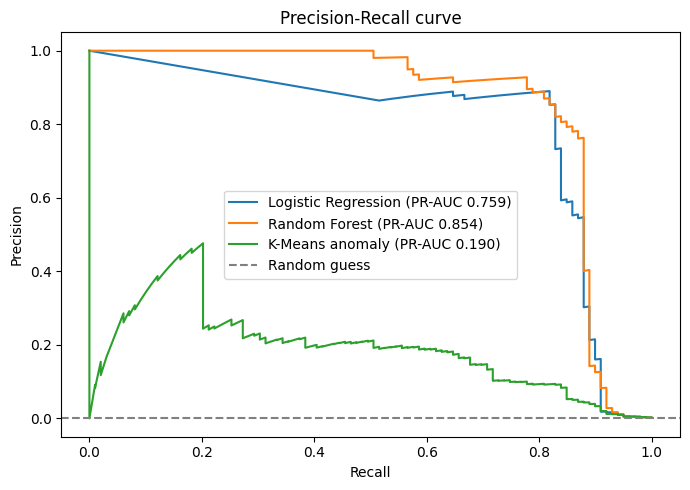

In [11]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, sc in [("Logistic Regression", p_lr_test),
                 ("Random Forest", p_rf_test),
                 ("K-Means anomaly", s_km_test)]:
    prec, rec, _ = precision_recall_curve(y_test, sc)
    ap = average_precision_score(y_test, sc)
    ax.plot(rec, prec, label=f"{name} (PR-AUC {ap:.3f})")

ax.axhline(y_test.mean(), linestyle="--", color="gray", label="Random guess")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall curve")
ax.legend()
plt.tight_layout()
plt.savefig("pr_curve.png", dpi=150)
plt.show()

## 11. Cost-based threshold analysis

**Business logic**
- A **missed fraud** costs the transaction amount (money lost).
- A **false alarm** costs a fixed handling amount (analyst time, customer friction).
- The best threshold is the one with the **lowest total cost**.

**Assumptions (not from the dataset):**
1. `FALSE_ALARM_COST` is an assumed number. Change it to match a real business.
2. A fraud we flag is fully stopped; a fraud we miss loses its full amount.
3. Amounts are in the dataset's currency units.

The threshold is chosen on the **validation** set and the savings are reported on the **test** set.

In [12]:
FALSE_ALARM_COST = 5   # ASSUMPTION: replace with a realistic value for your case

def total_cost(y_true, proba, amount, thr, fa_cost):
    actual = y_true.values
    flagged = proba >= thr
    missed = (actual == 1) & (~flagged)
    false_alarms = (actual == 0) & flagged
    cost = amount[missed].sum() + fa_cost * false_alarms.sum()
    return cost, int(missed.sum()), int(false_alarms.sum())

# Pick the better of the two supervised models using validation PR-AUC
candidates = {
    "Logistic Regression": (p_lr_val, p_lr_test),
    "Random Forest": (p_rf_val, p_rf_test),
}
best_name = max(candidates, key=lambda m: average_precision_score(y_val, candidates[m][0]))
p_val, p_test = candidates[best_name]
print("Model used for cost analysis:", best_name)

thresholds = np.linspace(0.01, 0.99, 99)

def best_threshold(fa_cost):
    costs = [total_cost(y_val, p_val, amt_val, t, fa_cost)[0] for t in thresholds]
    return thresholds[int(np.argmin(costs))]

best_thr = best_threshold(FALSE_ALARM_COST)

cost_none = amt_test[y_test.values == 1].sum()                       # no model at all
cost_def, miss_def, fa_def = total_cost(y_test, p_test, amt_test, 0.5, FALSE_ALARM_COST)
cost_best, miss_best, fa_best = total_cost(y_test, p_test, amt_test, best_thr, FALSE_ALARM_COST)

summary = pd.DataFrame({
    "Strategy": ["No fraud model", "Model at 0.5 threshold", f"Model at tuned threshold ({best_thr:.2f})"],
    "Missed frauds": [int(y_test.sum()), miss_def, miss_best],
    "False alarms": [0, fa_def, fa_best],
    "Total cost": [cost_none, cost_def, cost_best],
}).set_index("Strategy")
display(summary)

print(f"Saving vs no model: {cost_none - cost_best:,.2f} "
      f"({(cost_none - cost_best) / cost_none * 100:.1f}%)")

Model used for cost analysis: Random Forest


,Missed frauds,False alarms,Total cost
Strategy,,,
No fraud model,99,0,"9,874.350"
Model at 0.5 threshold,19,12,"2,802.960"
Model at tuned threshold (0.32),16,20,"2,636.180"


Saving vs no model: 7,238.17 (73.3%)


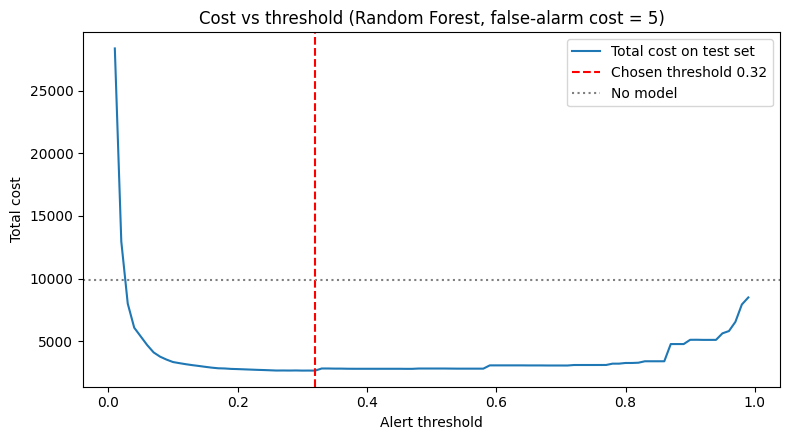

In [13]:
test_costs = [total_cost(y_test, p_test, amt_test, t, FALSE_ALARM_COST)[0] for t in thresholds]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(thresholds, test_costs, label="Total cost on test set")
ax.axvline(best_thr, linestyle="--", color="red", label=f"Chosen threshold {best_thr:.2f}")
ax.axhline(cost_none, linestyle=":", color="gray", label="No model")
ax.set_xlabel("Alert threshold")
ax.set_ylabel("Total cost")
ax.set_title(f"Cost vs threshold ({best_name}, false-alarm cost = {FALSE_ALARM_COST})")
ax.legend()
plt.tight_layout()
plt.savefig("cost_vs_threshold.png", dpi=150)
plt.show()

## 12. Sensitivity test: what if the false-alarm cost is different?

The false-alarm cost is an assumption, so we test a range of values. These values are test inputs, not facts about any real bank.

In [14]:
rows = []
for fa in [1, 5, 10, 25, 50, 100]:
    thr = best_threshold(fa)
    cost, missed, false_alarms = total_cost(y_test, p_test, amt_test, thr, fa)
    rows.append({
        "False-alarm cost": fa,
        "Best threshold": thr,
        "Missed frauds": missed,
        "False alarms": false_alarms,
        "Total cost": cost,
        "Saving vs no model": cost_none - cost,
        "Saving %": (cost_none - cost) / cost_none * 100,
    })
sens = pd.DataFrame(rows).set_index("False-alarm cost")
display(sens)
sens.to_csv("sensitivity_results.csv")

,Best threshold,Missed frauds,False alarms,Total cost,Saving vs no model,Saving %
False-alarm cost,,,,,,
1,0.030,8,1211,"3,144.910","6,729.440",68.151
5,0.320,16,20,"2,636.180","7,238.170",73.303
10,0.320,16,20,"2,736.180","7,138.170",72.290
25,0.450,18,13,"3,043.060","6,831.290",69.182
50,0.450,18,13,"3,368.060","6,506.290",65.891
100,0.450,18,13,"4,018.060","5,856.290",59.308


## 13. Key numbers for the README

In [15]:
print("Fraud rate overall: %.3f%%" % (y.mean() * 100))
print("Model used for cost analysis:", best_name)
print("False-alarm cost assumed:", FALSE_ALARM_COST)
print("Chosen threshold: %.2f" % best_thr)
print("Test-set loss with no model: %.2f" % cost_none)
print("Test-set loss with tuned model: %.2f" % cost_best)
print("Saving: %.2f (%.1f%%)" % (cost_none - cost_best, (cost_none - cost_best) / cost_none * 100))
print()
display(results)

Fraud rate overall: 0.173%
Model used for cost analysis: Random Forest
False-alarm cost assumed: 5
Chosen threshold: 0.32
Test-set loss with no model: 9874.35
Test-set loss with tuned model: 2636.18
Saving: 7238.17 (73.3%)



,Precision,Recall,F1,ROC_AUC,PR_AUC,Flagged
Model,,,,,,
Logistic Regression,0.062,0.909,0.116,0.968,0.759,1459
Random Forest,0.870,0.808,0.838,0.970,0.854,92
K-Means anomaly,0.112,0.717,0.194,0.968,0.190,633


## 14. Limitations

- Only ~0.17% of rows are fraud, so test-set results rest on a small number of fraud cases and can change with a different split.
- `V1`-`V28` are anonymised PCA features, so the model cannot be explained in business terms.
- `Time` covers about two days only; the hour analysis is approximate and may not reflect real daily patterns.
- The false-alarm cost is an assumption; real costs depend on the business (see the sensitivity table).
- The data is a European-cardholder sample from 2013, so results may not carry over to other markets or later fraud patterns.
- The cost model assumes a flagged fraud is fully prevented. Real systems stop only part of the loss.